# **Car Price Prediction – Regression Project**

**Target variable**: `price`

**Problem type**: `Supervised learning` – `Regression`


# **Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# **Load Dataset**

In [3]:
df = pd.read_csv("CarPrice_Assignment.csv")
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


# **Understand The Dataset**

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (205, 26)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0,103.000000,59.322565,1.00,52.00,103.00,154.00,205.00
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00
wheelbase,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90
carlength,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10
carwidth,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30
carheight,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80
curbweight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00
enginesize,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00
boreratio,205.0,3.329756,0.270844,2.54,3.15,3.31,3.58,3.94
stroke,205.0,3.255415,0.313597,2.07,3.11,3.29,3.41,4.17


In [7]:
df.isnull().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [8]:
df.duplicated().sum()

np.int64(0)

**Initial observations**
- The uploaded dataset contains **205 rows and 26 columns**.
- The target column is `price`.
- The dataset has no missing values and no duplicate rows.
- Both numerical and categorical variables are present.

# **Exploratory Data Analysis**

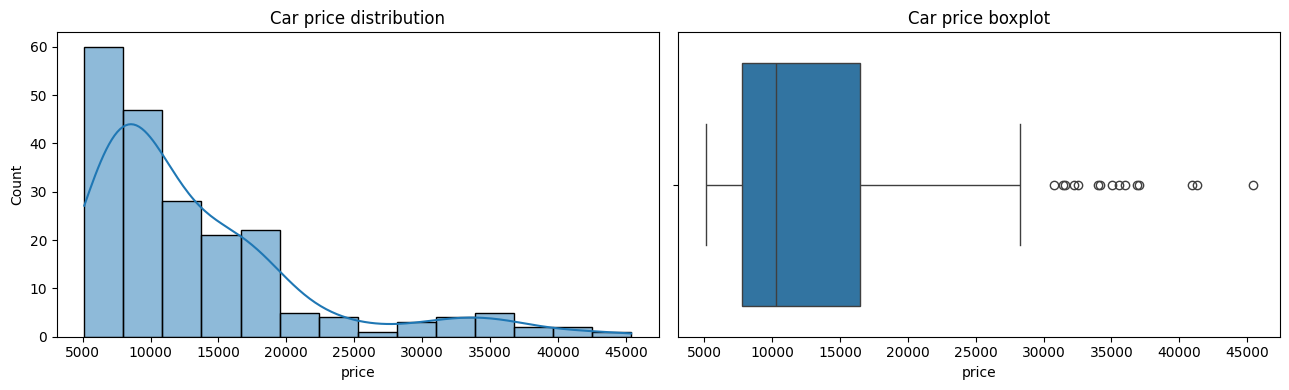

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], kde=True, ax=ax[0])
ax[0].set_title("Car price distribution")
sns.boxplot(x=df["price"], ax=ax[1])
ax[1].set_title("Car price boxplot")
plt.tight_layout(); plt.show()

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [Text(0, 0, 'car_ID'),
  Text(1, 0, 'symboling'),
  Text(2, 0, 'wheelbase'),
  Text(3, 0, 'carlength'),
  Text(4, 0, 'carwidth'),
  Text(5, 0, 'carheight'),
  Text(6, 0, 'curbweight'),
  Text(7, 0, 'enginesize'),
  Text(8, 0, 'boreratio'),
  Text(9, 0, 'stroke'),
  Text(10, 0, 'compressionratio'),
  Text(11, 0, 'horsepower'),
  Text(12, 0, 'peakrpm'),
  Text(13, 0, 'citympg'),
  Text(14, 0, 'highwaympg'),
  Text(15, 0, 'price')])

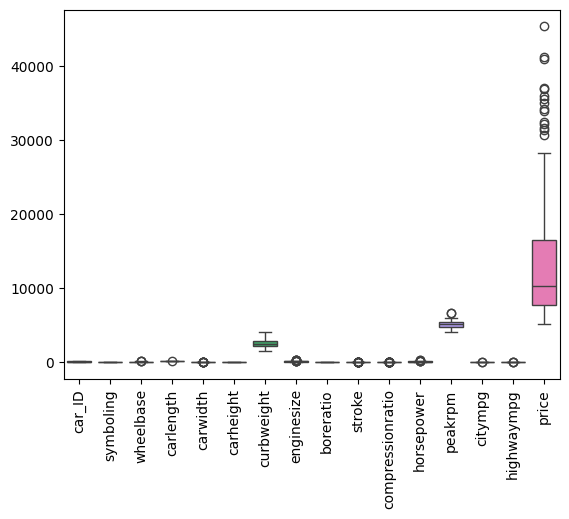

In [10]:
sns.boxplot(data=df)
plt.xticks(rotation=90)

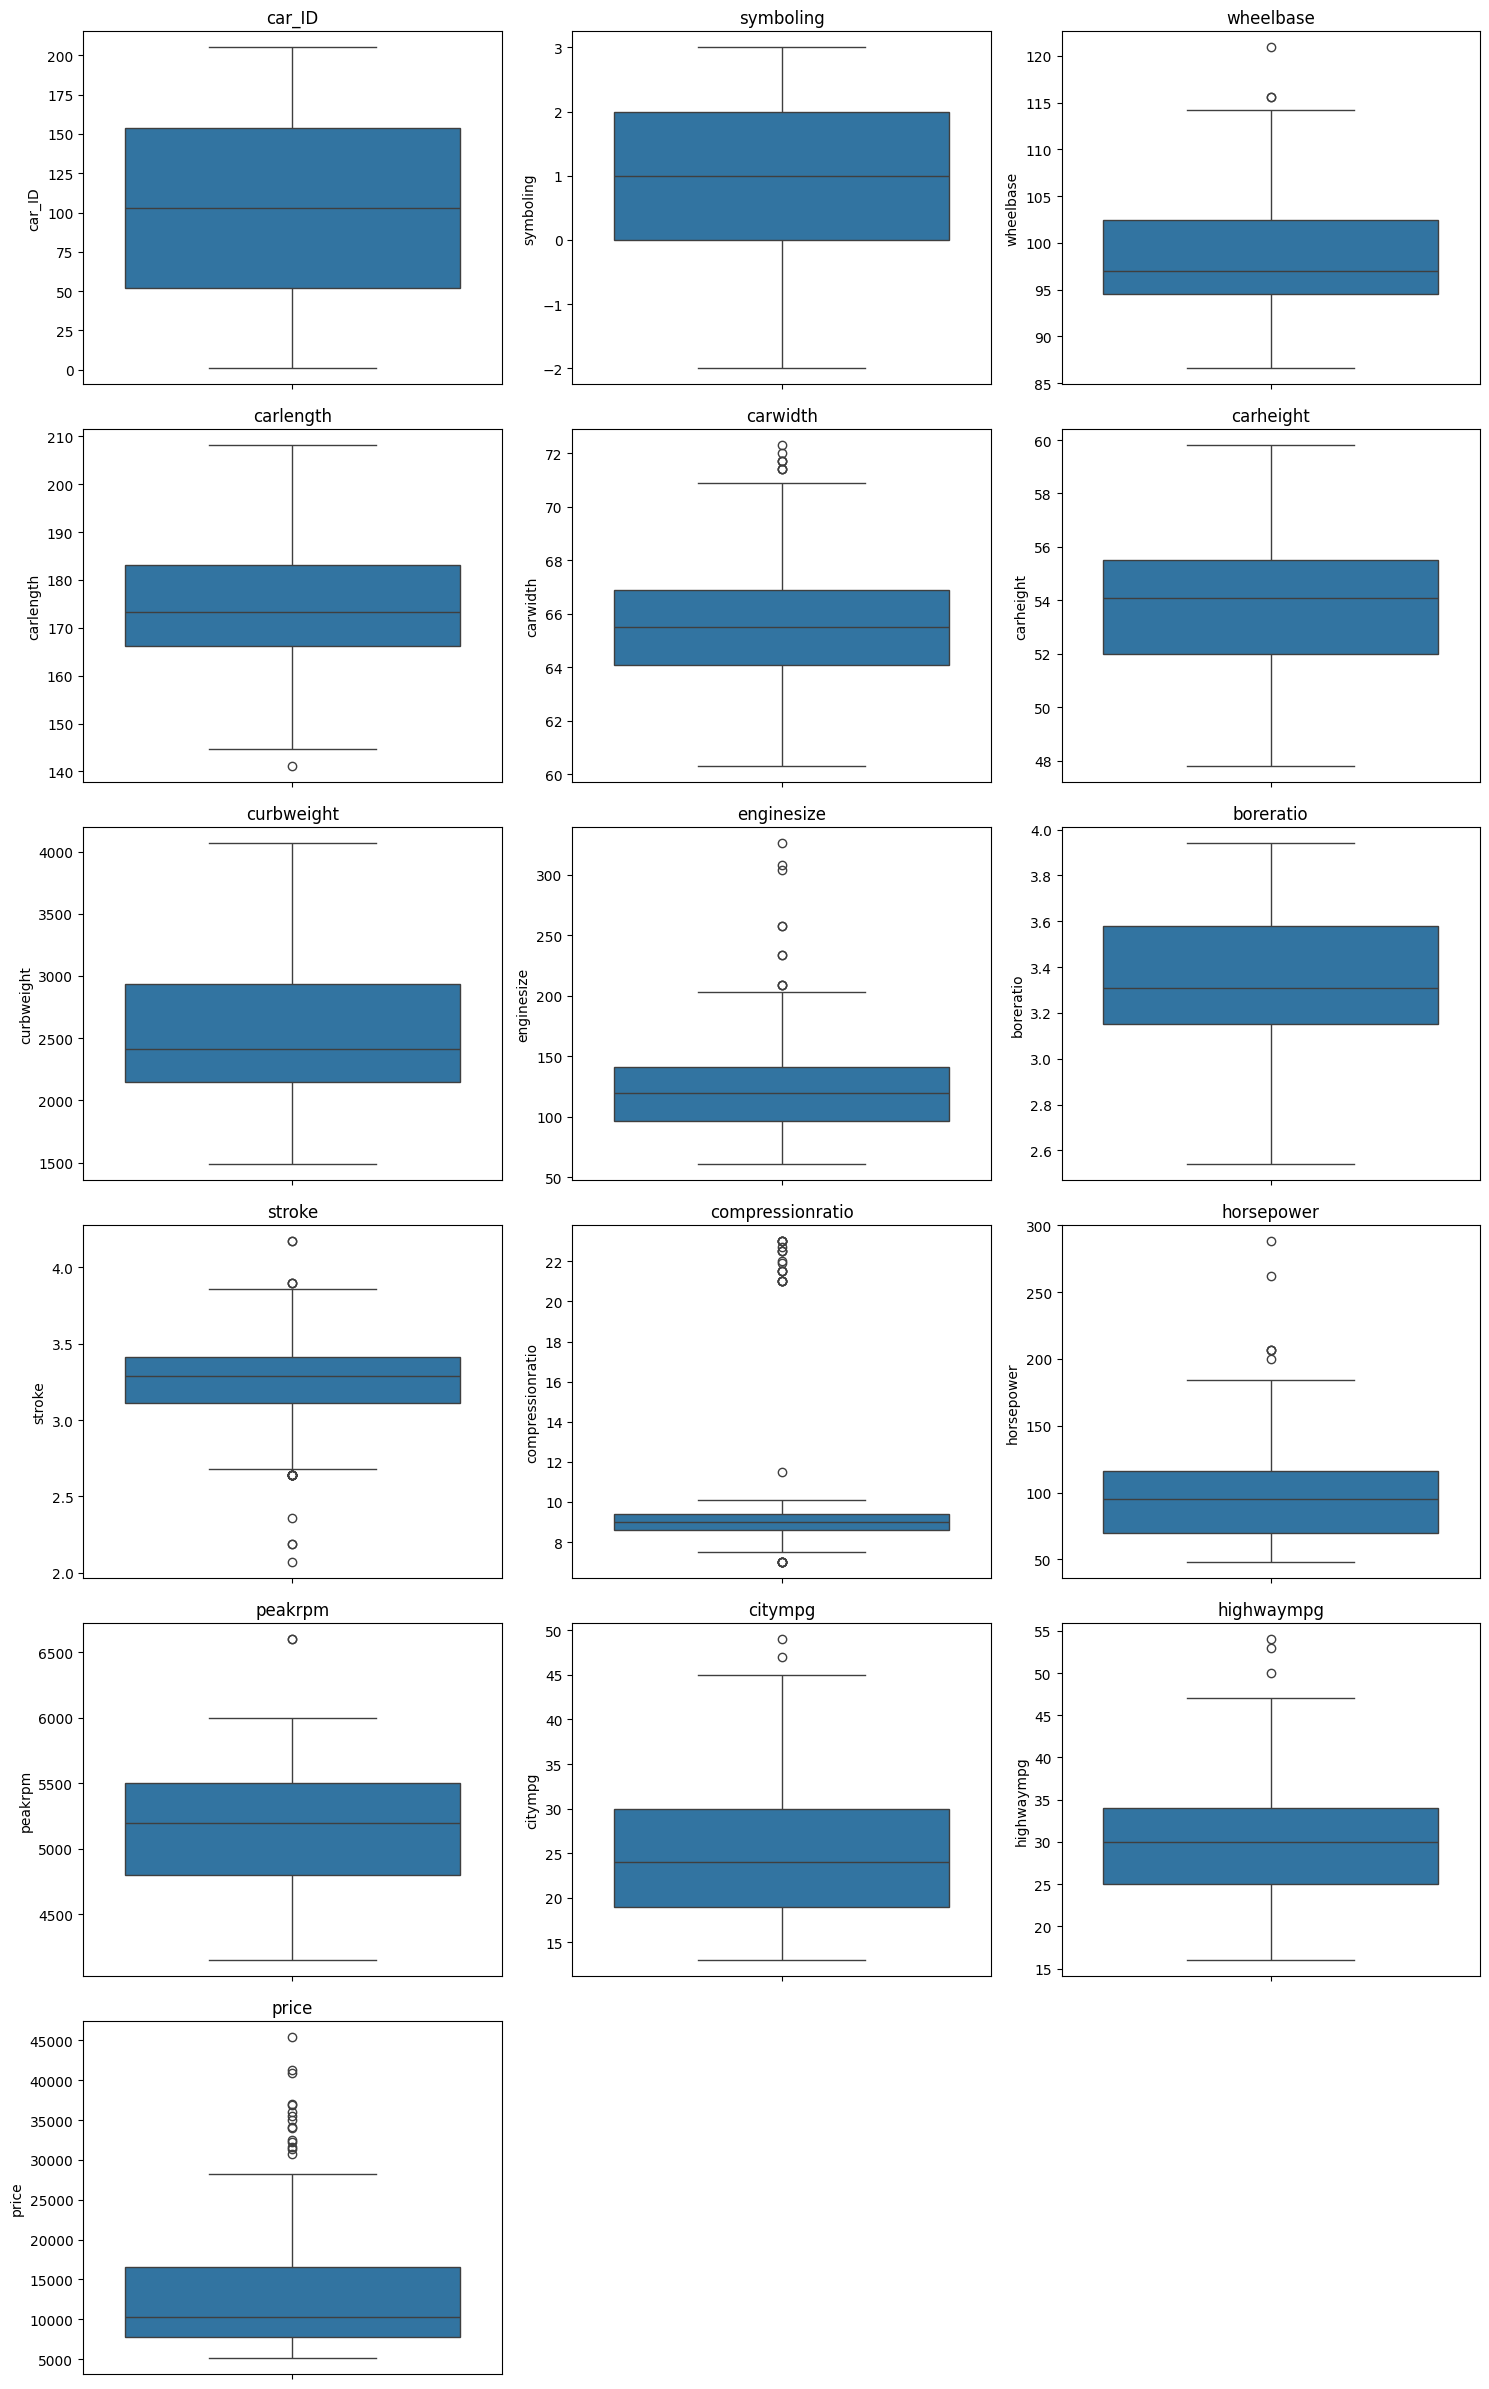

In [11]:
import math
numeric_cols = df.select_dtypes(include='number').columns

n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,figsize=(15, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

# Remove unused plots
for i in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [12]:
skew_kurt = pd.DataFrame({
    "skewness":df.skew(numeric_only=True),
    "kurtosis":df.kurt(numeric_only=True)
}).sort_values("skewness", key=lambda s: s.abs(), ascending=False)
display(skew_kurt)

# Interpretation: |skew| near 0 is approximately symmetric; large positive/negative values indicate asymmetry.
# High positive kurtosis indicates heavier tails / more extreme observations than a normal distribution.

,skewness,kurtosis
compressionratio,2.610862,5.233054
enginesize,1.947655,5.305682
price,1.777678,3.051648
horsepower,1.405310,2.684006
wheelbase,1.050214,1.017039
carwidth,0.904003,0.702764
stroke,-0.689705,2.174396
curbweight,0.681398,-0.042854
citympg,0.663704,0.578648
highwaympg,0.539997,0.440070


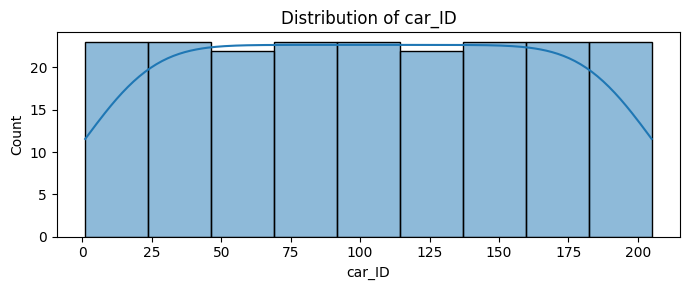

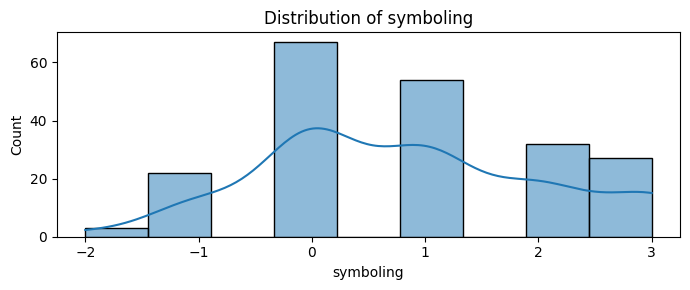

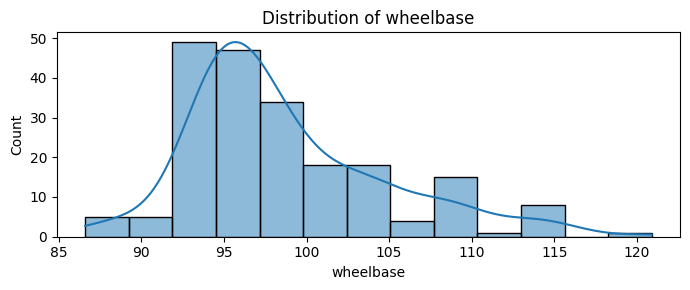

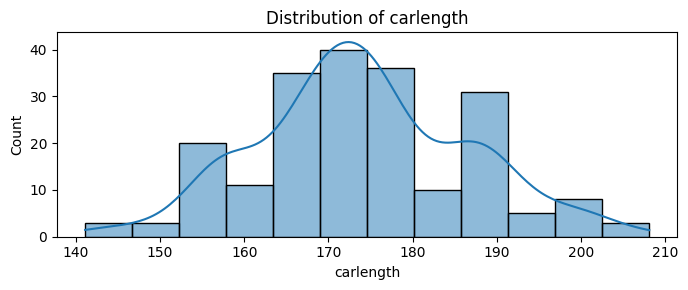

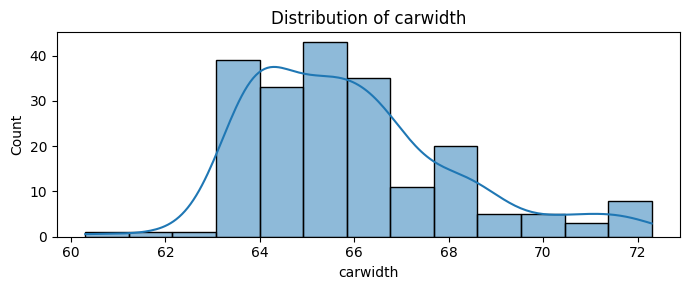

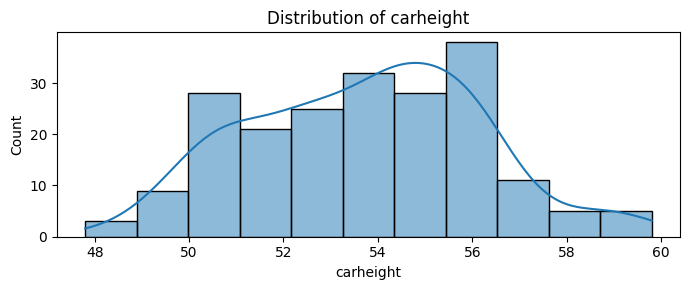

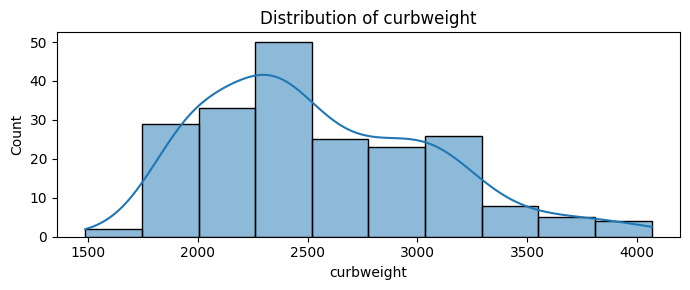

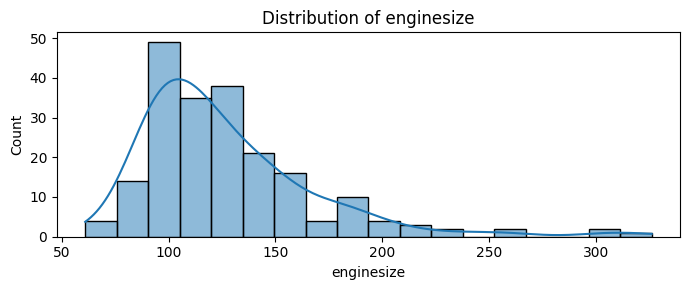

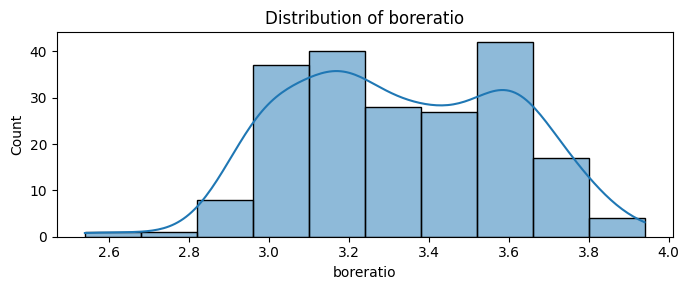

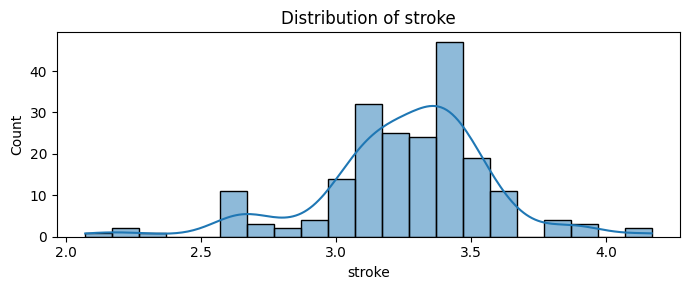

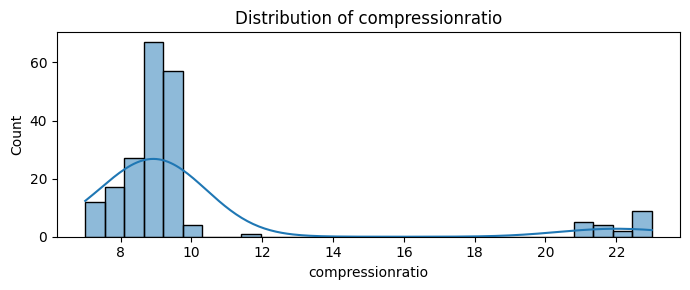

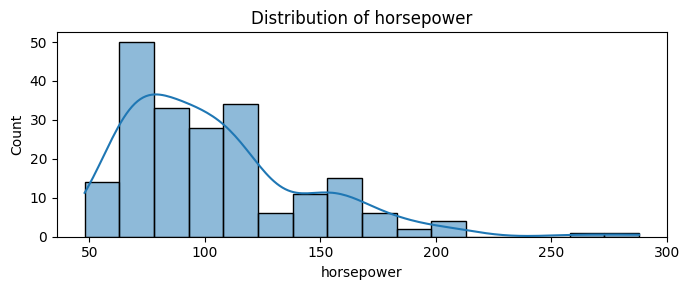

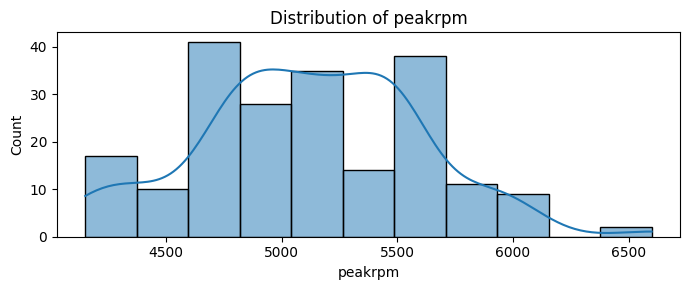

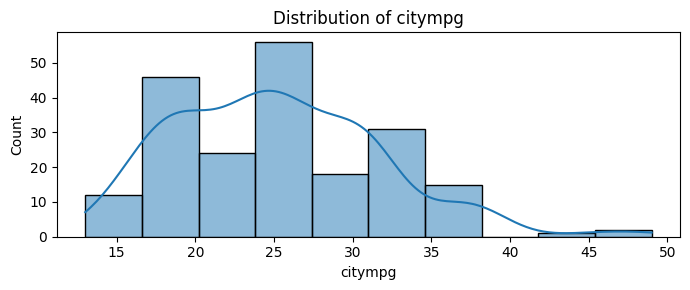

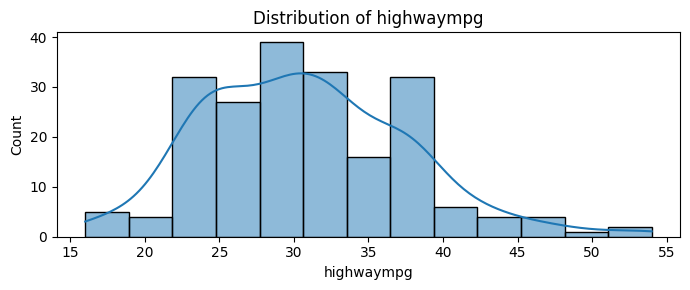

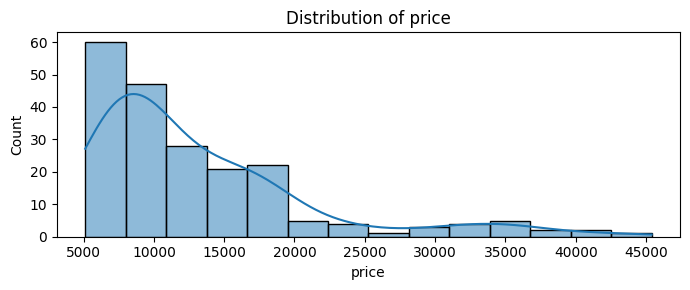

In [13]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
for col in num_cols:
    plt.figure(figsize=(7, 3))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout(); plt.show()

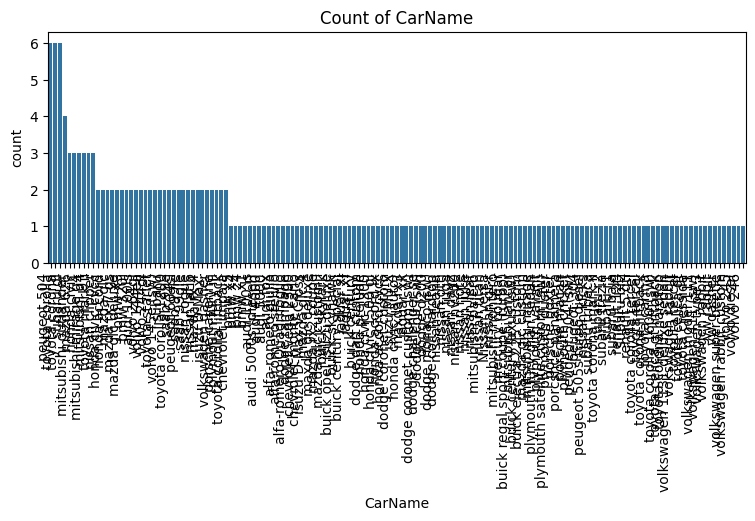

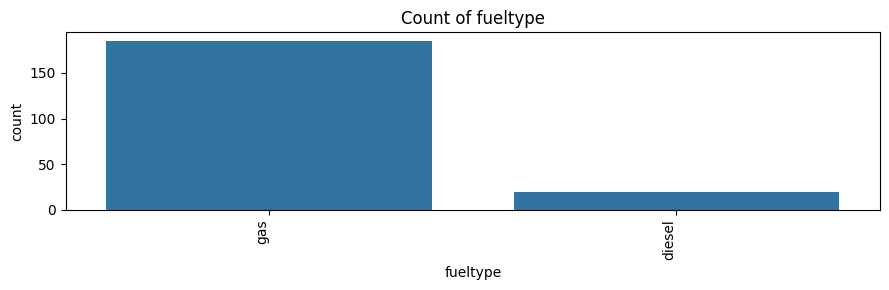

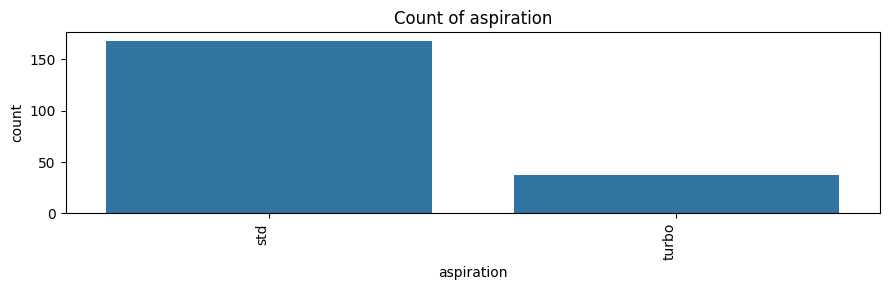

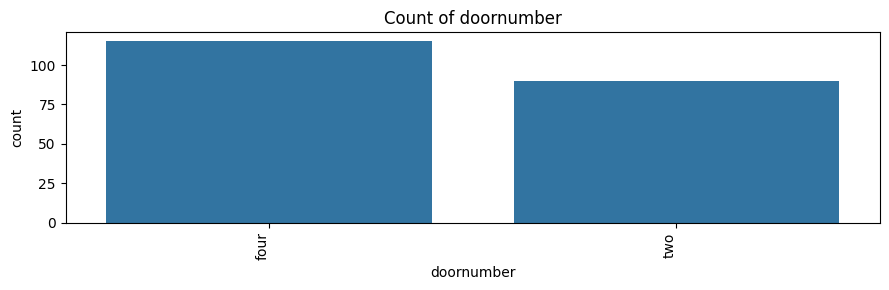

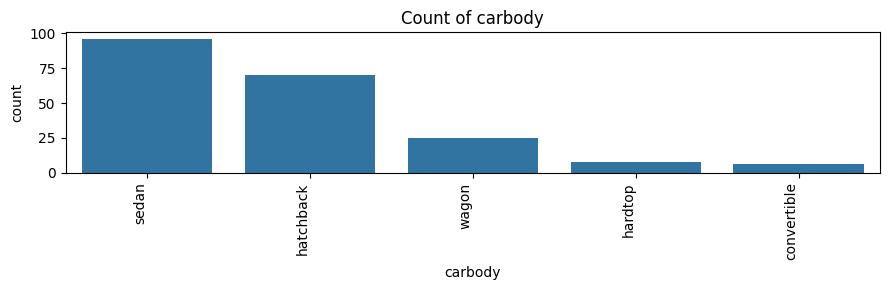

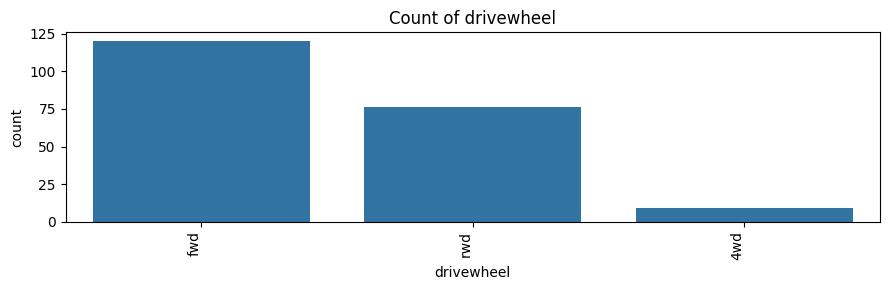

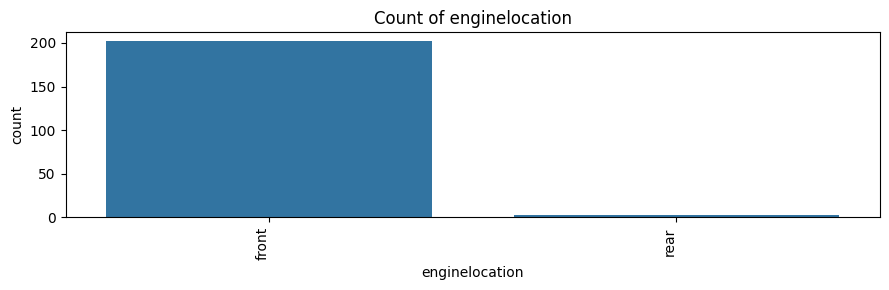

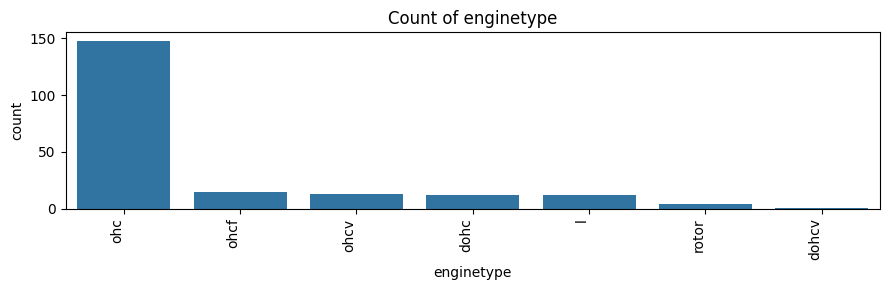

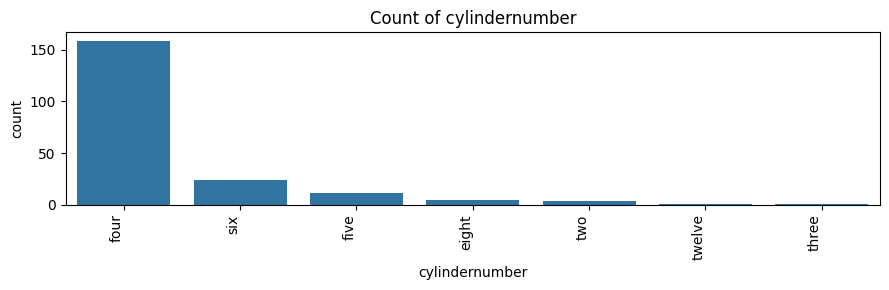

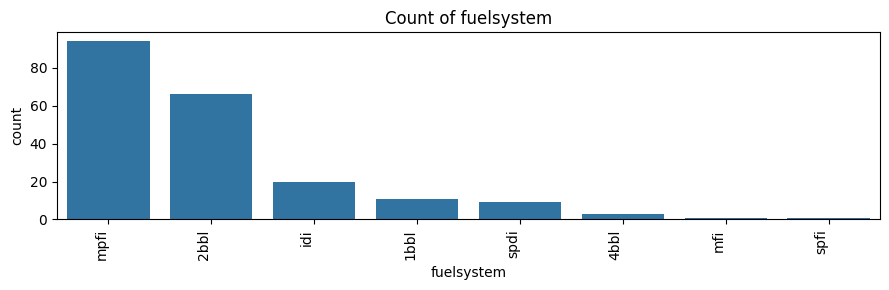

In [14]:
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
for col in cat_cols:
    plt.figure(figsize=(9, 3))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.title(f"Count of {col}"); plt.xticks(rotation=90, ha="right")
    plt.tight_layout(); plt.show()

Correlation with price:
 price               1.000000
enginesize          0.874145
curbweight          0.835305
horsepower          0.808139
carwidth            0.759325
carlength           0.682920
wheelbase           0.577816
boreratio           0.553173
carheight           0.119336
stroke              0.079443
compressionratio    0.067984
symboling          -0.079978
peakrpm            -0.085267
car_ID             -0.109093
citympg            -0.685751
highwaympg         -0.697599
Name: price, dtype: float64


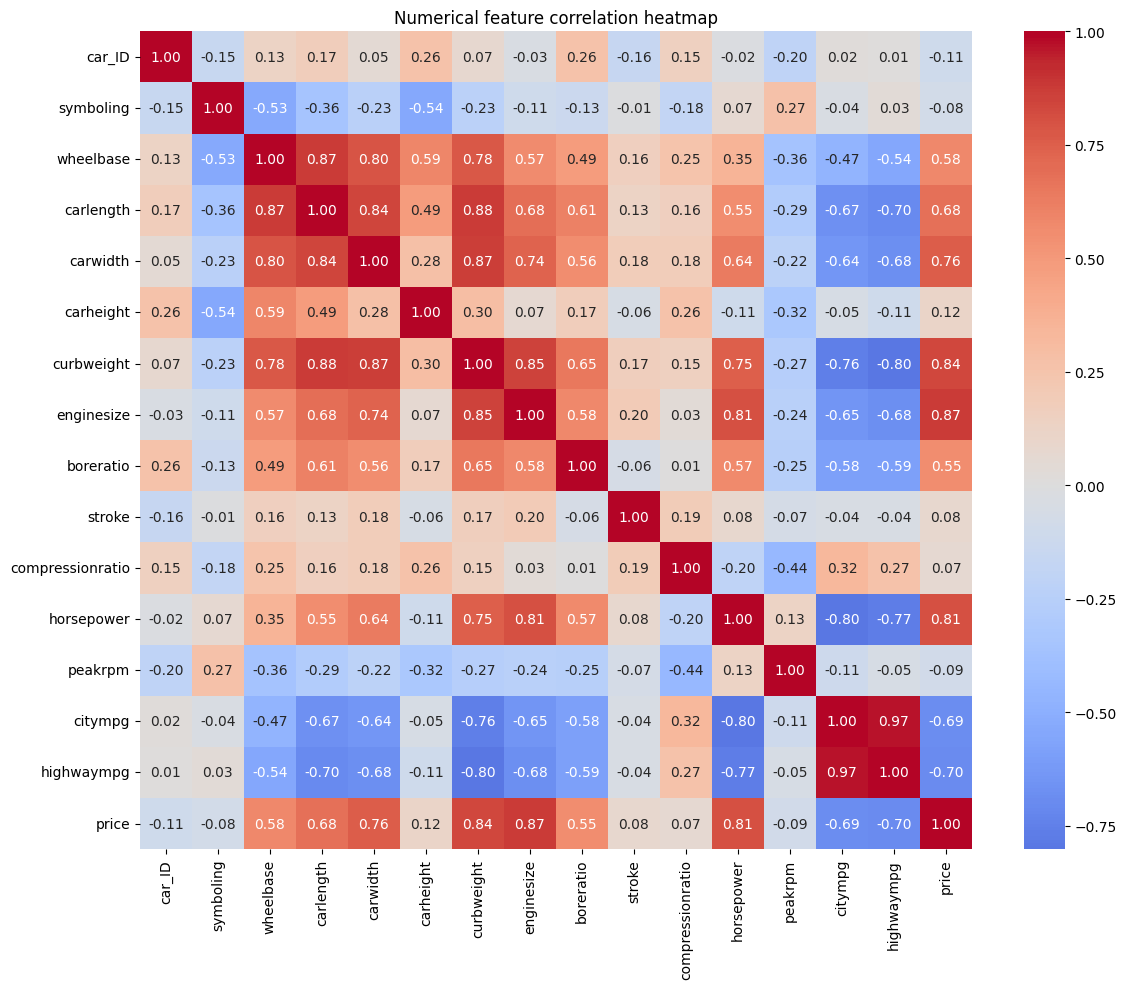

In [15]:
corr_matrix = df.select_dtypes(include='number').corr()
print("Correlation with price:\n", corr_matrix['price'].sort_values(ascending=False))

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Numerical feature correlation heatmap")
plt.tight_layout()
plt.show()

# **Data Preprocessing**

In [16]:
df["brand"] = df["CarName"].str.split().str[0].str.lower()
df["brand"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

In [17]:
brand_corrections = {
    "maxda": "mazda",
    "porcshce": "porsche",
    "toyouta": "toyota",
    "vokswagen": "volkswagen",
    "vw": "volkswagen"
}
df["brand"] = df["brand"].replace(brand_corrections)
df["brand"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

In [18]:
X = df.drop(columns=['price', 'car_ID','brand'])
y = df['price']
X.head()

,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,...,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg
0,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,...,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27
1,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,...,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27
2,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,...,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26
3,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,...,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30
4,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,...,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22


In [19]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Categorical features: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']


In [20]:
cat_cols = X.select_dtypes(include='object').columns
X = pd.get_dummies(X,columns=cat_cols,drop_first=True,dtype='int64')
print(X.shape)

(205, 189)


In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (164, 189)
X_test : (41, 189)
y_train: (164,)
y_test : (41,)


In [22]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

**Preprocessing Steps**

- Create a brand feature from CarName.
- Correct a few spelling variations in brand names.
- Remove car_ID because it is only an identifier.
- Remove CarName after extracting the brand.
- Separate the independent variables (X) and target (y).
- Split the data into training and testing sets.
- encode categorical features and Standardizes numerical features

# **Model Implementation**

In [23]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100,random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,random_state=42),
    "Support Vector": SVR()
}

In [27]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
results = {}
for name, model in models.items():
    if name in ["Linear Regression", "Support Vector"]:
        scaler = StandardScaler()
        X_train_model = scaler.fit_transform(X_train)
        X_test_model = scaler.transform(X_test)
    else:
        X_train_model = X_train
        X_test_model = X_test

    model.fit(X_train_model, y_train)
    y_pred = model.predict(X_test_model)

    results[name] = {
        "R2 Score": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    }

    print(f"\n{name}")
    print("R2 Score:", results[name]["R2 Score"])
    print("MAE:", results[name]["MAE"])
    print("MSE:", results[name]["MSE"])
    print("RMSE:", results[name]["RMSE"])


Linear Regression
R2 Score: 0.49245455114619097
MAE: 4160.851580227418
MSE: 40067678.511690326
RMSE: 6329.903515195972

Decision Tree
R2 Score: 0.855897691975291
MAE: 2200.1422682926827
MSE: 11376015.613509487
RMSE: 3372.834952011362

Random Forest
R2 Score: 0.9534566623613863
MAE: 1365.3525121951218
MSE: 3674318.218351683
RMSE: 1916.8511205494503

Gradient Boosting
R2 Score: 0.9305972928856937
MAE: 1700.9865846172768
MSE: 5478928.75953656
RMSE: 2340.711165337697

Support Vector
R2 Score: -0.10170857834104075
MAE: 5705.033285012664
MSE: 86973305.01185308
RMSE: 9325.947941729735


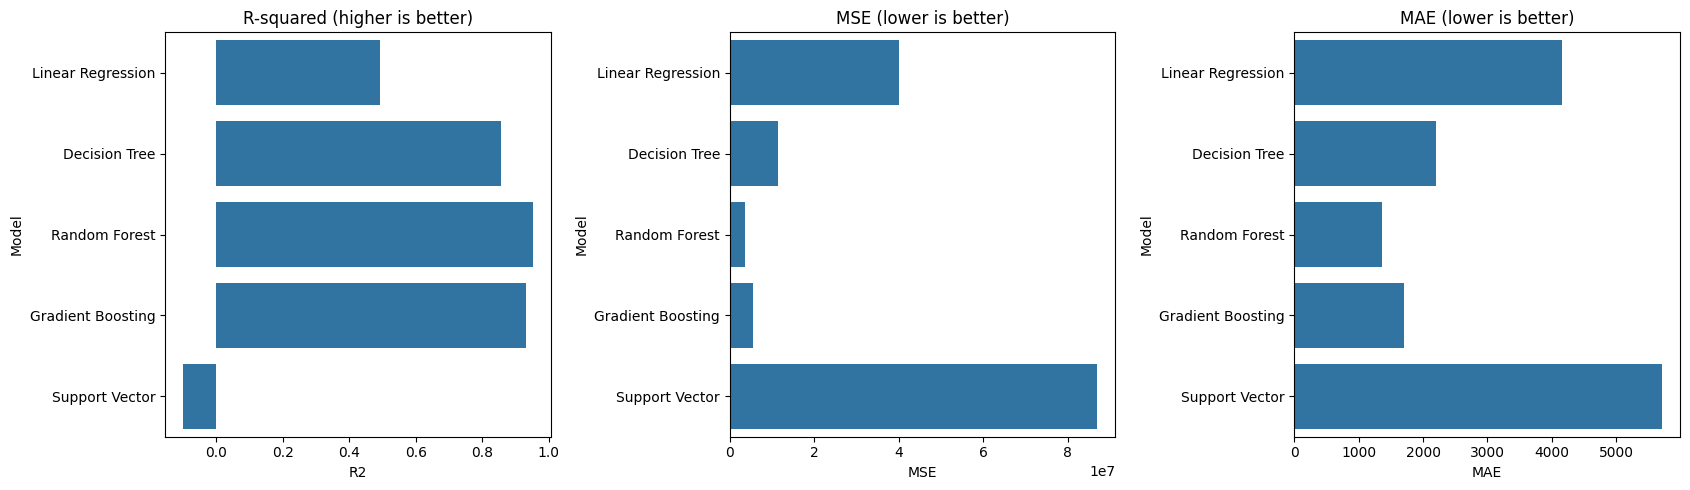

Best model based on test R2: Random Forest


In [28]:
# Convert results dictionary to a DataFrame for plotting
results_df = pd.DataFrame.from_dict(results, orient='index').reset_index()
results_df.rename(columns={'index': 'Model', 'R2 Score': 'R2'}, inplace=True)

# Visual comparison of evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=results_df, x="R2", y="Model", ax=axes[0])
axes[0].set_title("R-squared (higher is better)")

sns.barplot(data=results_df, x="MSE", y="Model", ax=axes[1])
axes[1].set_title("MSE (lower is better)")

sns.barplot(data=results_df, x="MAE", y="Model", ax=axes[2])
axes[2].set_title("MAE (lower is better)")

plt.tight_layout()
plt.show()

# Find the best baseline model based on R2
best_model_df = results_df.sort_values(by="R2", ascending=False).reset_index(drop=True)
best_model_name = best_model_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Best model based on test R2:", best_model_name)

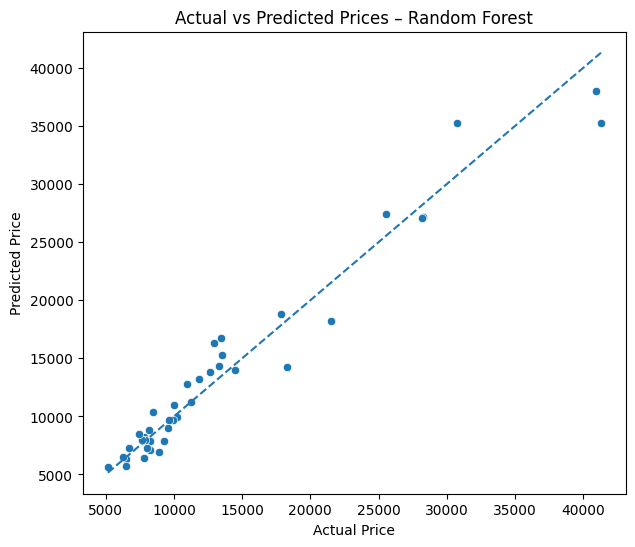

In [29]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions)
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Prices – {best_model_name}")
plt.show()


**Model Implementation and Evaluation – Insight**

- Five regression algorithms were implemented to predict car prices: Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor and Support Vector Regressor.

- Feature scaling was applied to Linear Regression and Support Vector Regression because these algorithms can be sensitive to differences in feature magnitudes. Tree-based algorithms were trained without feature scaling.

- All five models were evaluated using R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE) and Root Mean Squared Error (RMSE).

- A higher R² score indicates better explanatory performance, whereas lower MAE, MSE and RMSE indicate smaller prediction errors.

- The model with the highest R² and comparatively lowest error metrics will be considered the best-performing model for car price prediction.

# **Feature Importance**

In [30]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                              Feature  Importance
6                          enginesize    0.540808
5                          curbweight    0.294927
13                         highwaympg    0.043387
10                         horsepower    0.038275
3                            carwidth    0.013358
..                                ...         ...
118               CarName_subaru baja    0.000000
142          CarName_vokswagen rabbit    0.000000
147         CarName_volkswagen rabbit    0.000000
130  CarName_toyota corolla 1600 (sw)    0.000000
179              cylindernumber_three    0.000000

[189 rows x 2 columns]


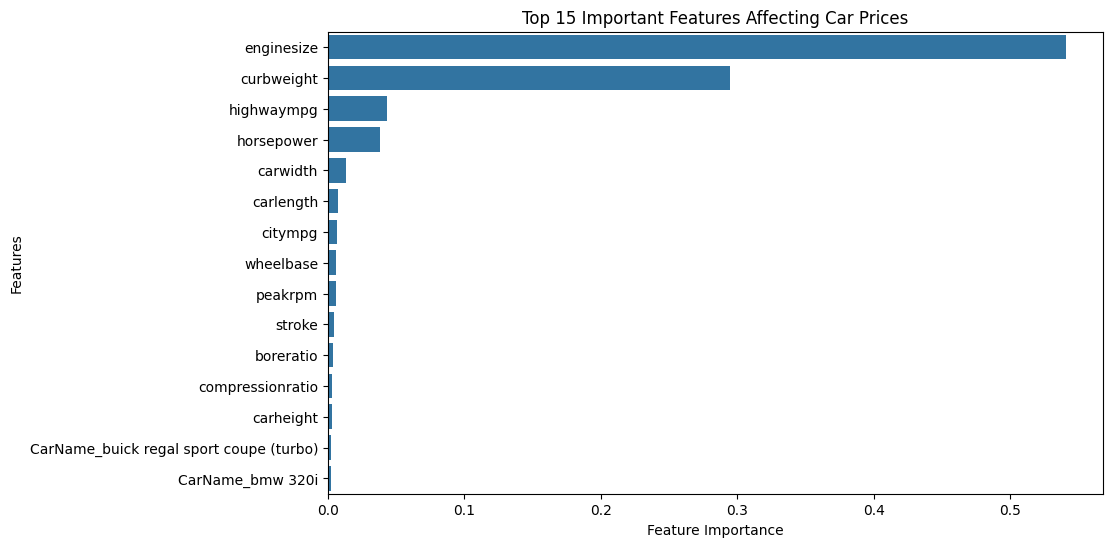

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features Affecting Car Prices')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.show()

In [32]:
top_features = feature_importance.head(10)['Feature'].tolist()

X_train_selected = X_train[top_features]
X_test_selected = X_test[top_features]

print("Selected Features:", top_features)
print("New Training Shape:", X_train_selected.shape)
print("New Testing Shape:", X_test_selected.shape)

Selected Features: ['enginesize', 'curbweight', 'highwaympg', 'horsepower', 'carwidth', 'carlength', 'citympg', 'wheelbase', 'peakrpm', 'stroke']
New Training Shape: (164, 10)
New Testing Shape: (41, 10)


**Feature Importance Analysis and Feature Selection – Insight**

- Random Forest Regressor was used to identify the important features affecting car prices. Feature importance scores were extracted and sorted in descending order.

- The analysis showed that engine size (`enginesize`) and curb weight (`curbweight`) were the most important features for predicting car prices.

- A bar plot was created to visualize the top 15 important features. Based on the feature importance scores, the top 10 features were selected for further model training.

- After feature selection, the training dataset contained 164 rows and 10 features, while the testing dataset contained 41 rows and 10 features.

- This process reduces the number of input features and focuses the model on the most informative variables.

# **Hyperparameter Tuning**

In [33]:
param_grids = {
    'Linear Regression': {
        'fit_intercept': [True, False]
    },

    'Decision Tree': {
        'max_depth': [None, 5, 10, 15],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },

    'Random Forest': {
        'n_estimators': [100, 200,300],
        'max_depth': [None, 10, 20,30],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },

    'Gradient Boosting': {
        'n_estimators': [100, 200,300],
        'learning_rate': [0.05, 0.1],
        'max_depth': [3, 5]
    },

    'Support Vector': {
        'C': [0.1, 1, 10],
        'epsilon': [0.01, 0.1, 0.2],
        'kernel': ['linear', 'rbf']
    }
}

In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

tuned_results = []
best_models = {}

for name, model in models.items():

    print("\nTuning:", name)

    if name in ['Linear Regression', 'Support Vector']:

        scaler = StandardScaler()

        X_train_model = scaler.fit_transform(X_train)
        X_test_model = scaler.transform(X_test)

    else:
        X_train_model = X_train
        X_test_model = X_test

    # Before tuning
    model.fit(X_train_model, y_train)

    y_pred_before = model.predict(X_test_model)

    r2_before = r2_score(y_test, y_pred_before)
    rmse_before = np.sqrt(mean_squared_error(y_test, y_pred_before))
    mae_before = mean_absolute_error(y_test, y_pred_before)
    mse_before = mean_squared_error(y_test, y_pred_before)

    print("R2 Before:", r2_before)

    # GridSearchCV
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    grid.fit(X_train_model, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    # After tuning
    y_pred_after = best_model.predict(X_test_model)

    r2_after = r2_score(y_test, y_pred_after)
    mae_after = mean_absolute_error(y_test, y_pred_after)
    mse_after = mean_squared_error(y_test, y_pred_after)
    rmse_after = np.sqrt(mean_squared_error(y_test, y_pred_after))

    tuned_results.append({
        'Model': name,
        'R2 Before': r2_before,
        'R2 After': r2_after,
        'MAE After': mae_after,
        'MAE Before': mae_before,
        'MSE After': mse_after,
        'MSE Before': mse_before,
        'RMSE Before': rmse_before,
        'RMSE After': rmse_after,
        'Best Parameters': grid.best_params_
    })

    print("Best Parameters:", grid.best_params_)
    print("R2 Before:", r2_before)
    print("R2 After:", r2_after)
    print("RMSE After:", rmse_after)
    print("MAE After:", mae_after)
    print("MSE After:", mse_after)


Tuning: Linear Regression
R2 Before: 0.49245455114619097
Best Parameters: {'fit_intercept': True}
R2 Before: 0.49245455114619097
R2 After: 0.49245455114619097
RMSE After: 6329.903515195972
MAE After: 4160.851580227418
MSE After: 40067678.511690326

Tuning: Decision Tree
R2 Before: 0.855897691975291
Best Parameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10}
R2 Before: 0.855897691975291
R2 After: 0.9135404163161235
RMSE After: 2612.559507377096
MAE After: 1837.0976835075494
MSE After: 6825467.179586454

Tuning: Random Forest
R2 Before: 0.9534566623613863
Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
R2 Before: 0.9534566623613863
R2 After: 0.954538037581106
RMSE After: 1894.4524566289285
MAE After: 1338.711926651825
MSE After: 3588950.110427382

Tuning: Gradient Boosting
R2 Before: 0.9305972928856937
Best Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
R2 Before: 0.93059729288569

In [35]:
results_df = pd.DataFrame(tuned_results)
results_df

,Model,R2 Before,R2 After,MAE After,MAE Before,MSE After,MSE Before,RMSE Before,RMSE After,Best Parameters
0,Linear Regression,0.492455,0.492455,4160.851580,4160.851580,4.006768e+07,4.006768e+07,6329.903515,6329.903515,{'fit_intercept': True}
1,Decision Tree,0.855898,0.913540,1837.097684,2200.142268,6.825467e+06,1.137602e+07,3372.834952,2612.559507,"{'max_depth': None, 'min_samples_leaf': 4, 'mi..."
2,Random Forest,0.953457,0.954538,1338.711927,1365.352512,3.588950e+06,3.674318e+06,1916.851121,1894.452457,"{'max_depth': None, 'min_samples_leaf': 2, 'mi..."
3,Gradient Boosting,0.930597,0.931745,1661.130278,1700.986585,5.388345e+06,5.478929e+06,2340.711165,2321.280886,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
4,Support Vector,-0.101709,0.640600,2986.971695,5705.033285,2.837251e+07,8.697331e+07,9325.947942,5326.585012,"{'C': 10, 'epsilon': 0.01, 'kernel': 'linear'}"


# **Before and After Tuning Comparison**

In [36]:
best_model_result = results_df.sort_values(
    by='R2 After',
    ascending=False
)

print(best_model_result[['Model', 'R2 Before', 'R2 After', 'RMSE Before', 'RMSE After','MSE Before', 'MSE After', 'MAE Before', 'MAE After', 'Best Parameters']])

               Model  R2 Before  R2 After  RMSE Before   RMSE After  \
2      Random Forest   0.953457  0.954538  1916.851121  1894.452457   
3  Gradient Boosting   0.930597  0.931745  2340.711165  2321.280886   
1      Decision Tree   0.855898  0.913540  3372.834952  2612.559507   
4     Support Vector  -0.101709  0.640600  9325.947942  5326.585012   
0  Linear Regression   0.492455  0.492455  6329.903515  6329.903515   

     MSE Before     MSE After   MAE Before    MAE After  \
2  3.674318e+06  3.588950e+06  1365.352512  1338.711927   
3  5.478929e+06  5.388345e+06  1700.986585  1661.130278   
1  1.137602e+07  6.825467e+06  2200.142268  1837.097684   
4  8.697331e+07  2.837251e+07  5705.033285  2986.971695   
0  4.006768e+07  4.006768e+07  4160.851580  4160.851580   

                                     Best Parameters  
2  {'max_depth': None, 'min_samples_leaf': 2, 'mi...  
3  {'learning_rate': 0.05, 'max_depth': 3, 'n_est...  
1  {'max_depth': None, 'min_samples_leaf': 4, 'mi... 

In [37]:
best_model_result = results_df.sort_values(
    by='R2 After',
    ascending=False
)

best_model_name = best_model_result.iloc[0]['Model']

best_model = best_models[best_model_name]

print("Best Model:", best_model_name)
print("Best R2 Score:", best_model_result.iloc[0]['R2 After'])
print("Best RMSE:", best_model_result.iloc[0]['RMSE After'])
print("Best MAE:", best_model_result.iloc[0]['MAE After'])
print("Best MSE:", best_model_result.iloc[0]['MSE After'])

Best Model: Random Forest
Best R2 Score: 0.954538037581106
Best RMSE: 1894.4524566289285
Best MAE: 1338.711926651825
Best MSE: 3588950.110427382


**Hyperparameter Tuning – Insight**

- Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation to identify the optimal parameters for all five regression models.

- The performance of each model was compared before and after tuning using R² Score, MAE, MSE and RMSE.

- The results showed that Decision Tree and Support Vector Regression achieved significant improvements after tuning, while Random Forest and Gradient Boosting showed smaller improvements. Linear Regression performance remained unchanged.

- Among all five models, Random Forest Regressor achieved the best performance with an R² score of 0.9545, MAE of 1338.71, MSE of 3588950.11 and RMSE of 1894.45.

- Therefore, Random Forest Regressor was selected as the best-performing model for car price prediction because it achieved the highest R² score and lowest prediction errors among the tuned models.

In [38]:
from sklearn.metrics import r2_score

train_pred = best_model.predict(X_train_model)
test_pred = best_model.predict(X_test_model)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("Training R2 Score:", train_r2)
print("Testing R2 Score:", test_r2)

difference = train_r2 - test_r2

if train_r2 < 0.50 and test_r2 < 0.50:
    print("Underfitting")

elif difference > 0.10:
    print("Overfitting")

else:
    print("Best Fit")

Training R2 Score: -0.4109419013054727
Testing R2 Score: -0.3382157283794345
Underfitting


**Insight**

- The initial model evaluation showed negative R² scores for both training (-0.4109) and testing (-0.3382).
- This indicates that the model was not learning the underlying patterns in the dataset effectively and performed worse than predicting the average car price. Therefore, the model showed underfitting.

In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(rf,param_grid,cv=5,scoring='r2',n_jobs=-1)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)
train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)

print("Training R2:", r2_score(y_train, train_pred))
print("Testing R2:", r2_score(y_test, test_pred))

Best Parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Training R2: 0.9761635916501461
Testing R2: 0.954538037581106


**Insight**

- After applying GridSearchCV to tune the Random Forest model, the training R² score improved to 0.9762 and the testing R² score improved to 0.9545.
 - The small difference between the scores indicates that the model learned the data patterns effectively and performs well on unseen data. Hyperparameter tuning significantly improved the model's performance and reduced the underfitting observed in the initial evaluation.

- **Conclusion:** Hyperparameter tuning helped improve the Random Forest model from underfitting to a good fit, with strong predictive performance and no significant signs of overfitting.

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1338.711926651825
MSE: 3588950.110427382
RMSE: 1894.4524566289285
R2 Score: 0.954538037581106


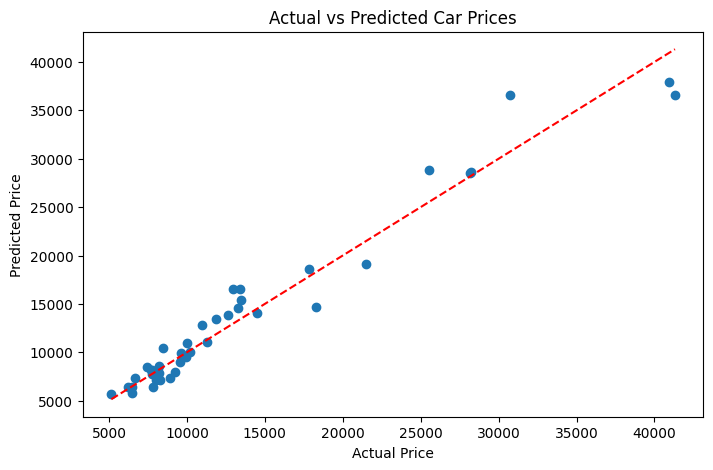

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.show()

**Insight – Actual vs Predicted Car Prices**

- The scatter plot compares the actual car prices with the prices predicted by the tuned Random Forest model.
- The red dashed line represents perfect predictions.
- Points closer to this line indicate more accurate predictions.
- The plot helps visualize how well the model predicts car prices.

In [42]:
import joblib

joblib.dump(best_model, "car_price_prediction_model.pkl")
print("Saved model: car_price_prediction_model.pkl")


Saved model: car_price_prediction_model.pkl


**Conclusion**
- The Car Price Prediction project successfully developed a machine learning regression model to predict car prices.
- Five regression algorithms were implemented and evaluated.
- After hyperparameter tuning using GridSearchCV, the Random Forest Regressor achieved the best performance, with a training R² score of 0.9762 and a testing R² score of 0.9545.
- The results show that Random Forest can predict car prices effectively using the selected features

# Car Price Prediction Using Machine Learning

## 1. Introduction

The main objective of this project is to predict car prices in the American market using machine learning regression algorithms.

A Chinese automobile company wants to enter the US automobile market by manufacturing cars locally. However, car prices in the US market may depend on different factors compared with the Chinese market.

Therefore, the company wants to understand which features significantly influence car prices and build a model that can predict car prices accurately.

**Insight:** This project helps the company understand the important factors affecting car prices and make better pricing and business decisions.

## 2. Dataset Description

The dataset contains 205 rows and 26 columns. It includes different car-related features such as engine size, horsepower, curb weight, fuel type, car width, car length, and price.

The target variable is **price**, which is the value we want to predict.

**Insight:** The dataset contains both numerical and categorical features that can help identify the relationship between car specifications and their prices.

## 3. Data Preprocessing

First, I performed data preprocessing to prepare the dataset for machine learning.

The main steps included:
- Separating independent variables (X) and the dependent variable (y).
- Identifying categorical features.
- Applying One-Hot Encoding to convert categorical variables into numerical format.
- Splitting the dataset into training and testing sets using an 80:20 ratio.

The training dataset contains 164 rows, and the testing dataset contains 41 rows.

**Insight:** Data preprocessing converted the dataset into a suitable format for machine learning algorithms and prepared separate datasets for model training and evaluation.

## 4. Model Building

I implemented five different regression algorithms:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor
5. Support Vector Regressor (SVR)

I evaluated these models using R² score, MAE, MSE, and RMSE.

**Insight:** Comparing multiple regression algorithms helped identify which model performs best for predicting car prices.

## 5. Feature Importance

I used the Random Forest Regressor to identify the most important features influencing car price predictions.

The top important features were:

- Engine Size
- Curb Weight
- Highway MPG
- Horsepower
- Car Width

Engine size and curb weight received the highest feature importance scores.

**Insight:** Engine size and curb weight are the most influential features in the Random Forest model's predictions. This suggests that these features play an important role in estimating car prices.

## 6. Feature Selection

Based on the feature importance results, I selected the top 10 important features for model building.

The selected features were:
- Engine Size
- Curb Weight
- Highway MPG
- Horsepower
- Car Width
- Car Length
- City MPG
- Wheelbase
- Peak RPM
- Stroke

The training dataset was reduced to 10 features while keeping the target variable unchanged.

**Insight:** Feature selection reduced the number of input variables and focused the model on the features that were most useful according to Random Forest feature importance.

## 7. Hyperparameter Tuning

After comparing the initial models, I applied GridSearchCV to tune the Random Forest model.

The best parameters obtained were:

- n_estimators = 300
- max_depth = 20
- min_samples_split = 2
- min_samples_leaf = 2

GridSearchCV used 5-fold cross-validation to identify a good combination of hyperparameters.

**Insight:** Hyperparameter tuning improved the model's predictive performance by finding a better combination of parameters.

## 8. Underfitting and Overfitting Analysis

During the initial evaluation, negative training and testing R² scores were observed when using a different set of feature variables. This indicated poor model performance for that evaluation.

After using the correctly trained tuned Random Forest model with the corresponding training and testing features, the results improved significantly.

- Training R² Score: 0.9762
- Testing R² Score: 0.9545

The difference between the training and testing scores is small.

**Insight:** The tuned model performs well on both training and unseen testing data, with no significant indication of overfitting or underfitting.

## 9. Final Model Evaluation

I evaluated the tuned Random Forest model using the following regression metrics:

- R² Score: 0.9545
- MAE: 1338.71
- MSE: 3,588,950.11
- RMSE: 1894.45

**Insight:** The testing R² score of approximately 95.45% indicates that the model explains a large proportion of the variation in car prices. The MAE and RMSE measure the prediction errors in the same price unit as the target variable.

## 10. Actual vs Predicted Price Visualization

Finally, I created a scatter plot to compare actual car prices with predicted car prices.

The red dashed line represents the ideal prediction line. Points closer to this line indicate that the predicted prices are closer to the actual prices.

**Insight:** The Actual vs Predicted plot provides a visual understanding of the model's prediction performance. Points close to the reference line indicate better prediction accuracy.

## 11. Final Conclusion

In this project, I developed a Car Price Prediction model using machine learning regression algorithms.

I started by understanding the business problem and exploring the dataset. Then, I performed data preprocessing, categorical encoding, model building, feature importance analysis, and feature selection.

I compared five regression algorithms and used GridSearchCV to tune the Random Forest model.

Finally, the tuned Random Forest Regressor achieved a training R² score of 0.9762 and a testing R² score of 0.9545.

Based on these results, Random Forest was selected as the best-performing model among the evaluated models.

**Overall, this project helped me understand how machine learning can be used to predict car prices and identify important features that influence pricing in the automobile market.**